<a href="https://colab.research.google.com/github/ikabrain/UCS772-CV-NLP-Lab/blob/main/NLP_assign5/NLP_assign5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5 - Sentiment Analysis using advanced methods
---

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence

SEED = 42

In [2]:
# Load keras's pre-processed IMDb Movie Review Dataset
NUM_WORDS = 10000
PAD, START, UNK, INDEX_FROM = 0, 1, 2, 3 # !IMPORTANT: shift is 0 = pad, 1 = start, 2 = unknown, real words start at 3

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=NUM_WORDS,
    start_char=START,
    oov_char=UNK,
    index_from=INDEX_FROM,
    seed=SEED
)

print("Training samples: ", len(X_train))
print("Testing samples: ", len(X_test))

print("Sentiment values: ", np.unique(y_train))

Training samples:  25000
Testing samples:  25000
Sentiment values:  [0 1]


In [3]:
MAX_LEN = 200

X_train = sequence.pad_sequences(X_train, maxlen=MAX_LEN, padding="pre", truncating="pre", value=PAD)
X_test = sequence.pad_sequences(X_test, maxlen=MAX_LEN, padding="pre", truncating="pre", value=PAD)

print("Training shape: ", X_train.shape)
print("Testing shape: ", X_test.shape)

Training shape:  (25000, 200)
Testing shape:  (25000, 200)


In [4]:
# Decoding one review back to words
word_index = imdb.get_word_index()

inv = {v + INDEX_FROM: k for k, v in word_index.items()}
inv.update({PAD: "<pad>", START: "<start>", UNK: "<unk>"})

print("First review:", " ".join(inv.get(t, "<unk>") for t in X_train[0] if t != PAD))
print("Its label:", y_train[0])

First review: plays the same kind of role in the <unk> bogart film the <unk> sadly i can kind of identify with mostel in that last chase scene where he and palance are being chased down by widmark douglas and half the new orleans police seeing the weight challenged zero trying to keep up with palance was something else because i'm kind of in <unk> league now in the <unk> department br br kazan kept the action going at a good clip there's very little down time in this film if there was any less it would be an indiana jones film panic in the streets won an oscar for best original screenplay that year br br kazan also made good use of the new orleans <unk> and the french quarter some of the same kinds of shots are later used in on the <unk> in fact panic in the streets is about people not <unk> when they really should in their own best interest very similar again to on the <unk> br br panic in the streets does everyone proud who was associated with it now why couldn't <unk> kazan get some

## Q1: Applying RNN & LSTM for Sentiment Analysis
---

Apply deep learning models i.e. RNN and LSTM for text classification for sentiment
analysis.

In [5]:
BATCH_SIZE = 64
EPOCHS = 10

In [6]:


# Loading pre-trained GloVe Embeddings
!pip install -q gensim

import gensim.downloader as api

kv = api.load("glove-wiki-gigaword-100")
print("No of KeyedVector: ", len(kv))
print("Size of each KeyedVector: ", kv.vector_size)

No of KeyedVector:  400000
Size of each KeyedVector:  100


In [7]:
# Building Embedding matrix to work with integer representation of words

rng = np.random.default_rng(SEED)
E = rng.normal(0, 0.1, (NUM_WORDS, kv.vector_size)).astype(np.float32)
E[PAD] = 0

hits = 0
for word, rank in word_index.items():
    i = rank + INDEX_FROM
    if i < NUM_WORDS and word in kv:
        E[i] = kv[word]
        hits += 1

print(f"GloVe coverage: {hits / (NUM_WORDS - INDEX_FROM):.1%}")

GloVe coverage: 98.0%


In [8]:
# Testing Embedding matrix throguh classic 'king - man + woman' example

def get_vector(word):
    # Retrieve word rank from IMDb word index and apply INDEX_FROM shift
    if word in word_index:
        idx = word_index[word] + INDEX_FROM
        if idx < NUM_WORDS:
            return E[idx]
    return None

def find_closest_words(vec, top_n=5):
    # Calculate cosine similarity of target vector against all embedding vectors in E
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    norms[norms == 0] = 1e-8  # Avoid division by zero
    normalized_E = E / norms

    vec_norm = np.linalg.norm(vec)
    if vec_norm == 0:
        return []
    normalized_vec = vec / vec_norm

    similarities = normalized_E @ normalized_vec
    closest_indices = np.argsort(similarities)[::-1]

    results = []
    for idx in closest_indices:
        if idx >= INDEX_FROM and idx < NUM_WORDS:
            # Recover the word from inverse mapping
            word = inv.get(idx, "<unk>")
            if word != "<unk>":
                results.append((word, similarities[idx]))
                if len(results) >= top_n:
                    break
    return results

# Get vectors for King, Man, and Woman
king_vec = get_vector("king")
man_vec = get_vector("man")
woman_vec = get_vector("woman")

if king_vec is not None and man_vec is not None and woman_vec is not None:
    # Perform classic analogy math: king - man + woman
    target_vec = king_vec - man_vec + woman_vec
    print("Analogy: 'king' - 'man' + 'woman' =")

    # Display closest results
    closest = find_closest_words(target_vec, top_n=5)
    for word, similarity in closest:
        print(f"  - {word}: {similarity:.4f}")
else:
    print("One of the words is outside the top 10,000 words limit.")

Analogy: 'king' - 'man' + 'woman' =
  - king: 0.8552
  - queen: 0.7834
  - throne: 0.6833
  - daughter: 0.6809
  - prince: 0.6713


### Designing Base Classes

In [9]:
class Layer:
    """
    Base class for RNN and Activation layers & cells of the neural network, iterating over per timestep or per sequence.
    """

    def __init__(self, trainable=True, seed=None) -> None:
        self.rng = np.random.default_rng(seed)
        self.built = False
        self.params = {}
        self.grads = {} if trainable else None


    # ----- Parameter Creation -----
    def __init_subclass__(cls, **kwargs):
        # Runs once when a subclass is defined (not when an object is created)
        super().__init_subclass__(**kwargs)
        child_build = cls.__dict__.get("build") # only a build this subclass wrote itself
        if child_build:
            def build(self, input_dim, *args, **kwargs):
                if not self.built:
                    child_build(self, input_dim, *args, **kwargs)
                    self.built = True
            cls.build = build

    def build(self, input_dim, *args, **kwargs):
        raise NotImplementedError # Defer param creation until shape of input is known

    def add_weight(self, name, shape=(1,), initializer=None, trainable=True):
        """
        Creates weight parameter to add to params after the input vector dims are known; to be used in self.build()
        """
        if initializer is None: # small random values as default
            initializer = lambda rng, shape: rng.normal(0, 0.1, shape)
        weight = np.float32(initializer(self.rng, shape)) # the cell's own rng, not passed by callers!
        self.params[name] = weight
        if trainable and self.grads is not None:
            self.grads[name] = np.zeros_like(weight) # frozen weights get no grad!
        return weight


    # ----- Forward Pass -----
    def forward(self, X, *args, **kwargs):
        raise NotImplementedError # build before forward

    def __call__(self, X, *args, **kwargs):
        return self.forward(X, **kwargs)


    # ----- Backpropagation -----
    def backward(self, dA, *args, **kwargs):
        # Here, dA is the activated gradient from the NEXT layer that has propagated to here for current output!
        raise NotImplementedError # returns gradient of loss wrt layer input

In [10]:
class RecurrentCell(Layer):
    """
    Base class for the Vanilla RNN and LSTM cells that compute forward and backward per timestep.

    TO DEFINE: build(input_dim), init_state(), forward(x_t, prev_state), backward(dstate, cache)
    """

    def __init__(self, hidden_size, frozen=False, seed=None) -> None:
        super().__init__(trainable=not frozen, seed=seed)
        self.hdim = hidden_size


    # --- Cell and/or Hidden State per-sequence helpers ---
    def init_state(self):
        raise NotImplementedError # returns a tuple of states initialized as zero arrays of size (1, hdim)

    def zero_dstate(self):
        """
        Helper function to initialize gradient of loss wrt state vectors to zero.
        """
        return tuple(np.zeros_like(s) for s in self.init_state()) # returns initial zero grad of loss wrt states; accumulates dstate in recurrent layers


    # --- Forward Pass at single timestep ---
    def forward(self, x_t, prev_state):
        raise NotImplementedError # returns (new_state, cache)

    def __call__(self, x_t, prev_state):
        return self.forward(x_t, prev_state)


    # --- Backpropagation at single timestep ---
    def backward(self, dstate, cache):
        raise NotImplementedError # returns (dx_t, dprev_state); accumulates self.grads

In [11]:
class Loss:
    """
    Base class for loss function.
    """

    def __init__(self, eps=1e-7):
        self.eps = eps # Small value to keep log & division away from 0

    def align(self, y_true, y_pred):
        """
        Reshapes y_true so that it broadcasts against y_pred, letting one label per sequence score all of its timesteps
        e.g. y_true (batch_size,) vs y_pred (batch_size, timesteps, 1) -> y_true (batch_size, 1, 1)
        """
        y_true = np.asarray(y_true)
        return y_true.reshape(y_true.shape + (1,) * (y_pred.ndim - y_true.ndim))

    def forward(self, y_true, y_pred):
        raise NotImplementedError

    def __call__(self, y_true, y_pred):
        return self.forward(y_true, y_pred)

    def backward(self):
        # Returns gradient of loss function wrt y_pred
        raise NotImplementedError

In [12]:
class Optimizer:
    """
    Base class for optimizers.
    """

    def __init__(self, lr=0.001):
        self.lr = lr

    def update(self, params: dict[str, np.ndarray], grads: dict[str, np.ndarray]):
        raise NotImplementedError

In [13]:
class Model:
    """
    Base class for model as a sequential combination of layers.
    """
    def __init__(self, layers = []):
        self.layers = layers
        self.loss = None

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def __call__(self, X):
        return self.forward(X)

    def backward(self, dA):
        for layer in reversed(self.layers):
            dA = layer.backward(dA)

    def train(self, X, y, loss_fn: Loss, optimizer: Optimizer, epochs):
        raise NotImplementedError

### Implementing RNN from scratch

In [14]:
class RNNCell(RecurrentCell):
    """
    Vanilla RNN cell.
    """

    def build(self, input_dim):
        self.xdim = input_dim
        self.add_weight("W_xh", (self.xdim, self.hdim))
        self.add_weight("W_hh", (self.hdim, self.hdim))
        self.add_weight("b", (1, self.hdim))

    def init_state(self):
        return (np.zeros((1, self.hdim)),)

    def forward(self, x_t, h_t_minus_1 = None):
        x_t = np.atleast_2d(x_t) # Input shape is (batches, input_dim)
        h_t_minus_1 = self.init_state()[0] if h_t_minus_1 is None else np.array(h_t_minus_1).reshape(-1, self.hdim)

        self.build(x_t.shape[-1])

        z_t = x_t @ self.params["W_xh"] + h_t_minus_1 @ self.params["W_hh"] + self.params["b"]
        h_t = np.tanh(z_t)

        new_state = (h_t,)
        cache = (x_t, h_t_minus_1, h_t)
        return (new_state, cache)

    def backward(self, dstate, cache):
        """
        Takes in gradients of current state @ t and values used in current run
        Returns gradient of current input (= previous layer's output) and previous state @ t-1
        """
        (dh_t,) = dstate # Gradient of loss wrt h_t (from activation/stacked RNN layer(s) placed on top of this one)
        (x_t, h_t_minus_1, h_t) = cache
        dpre = dh_t * (1 - h_t**2) # Gradient of loss wrt h_t times gradient of h_t wrt z_t = Derivative of tanh = 1-tanh^2

        if self.grads is not None: # Frozen cell skips accumulating grads, but still passes dx_t back!
            self.grads["W_xh"] += x_t.T @ dpre
            self.grads["W_hh"] += h_t_minus_1.T @ dpre
            self.grads["b"] += dpre.sum(axis=0, keepdims=True) # Sum over entire batch

        dx_t = dpre @ self.params["W_xh"].T
        dh_t_minus_1 = dpre @ self.params["W_hh"].T
        dprev_state = (dh_t_minus_1,)
        return (dx_t, dprev_state)

In [15]:
class RNNLayer(Layer):
    """
    RNN Layer that iterates for each time step per sequence.
    """

    def __init__(self, cell: RecurrentCell, return_sequences=False, seed=None) -> None:
        """
        If `return_sequences=False`, output is of shape `(batch_size, hidden_size)`.
        If `return_sequences=True` , output is of shape `(batch_size, timesteps, hidden_size)` i.e. output for each timestep.
        """
        super().__init__(seed=seed) # Assigns self.params & self.grads, which the setters below ignore!
        self.cell = cell
        self.return_sequences = return_sequences


    # --- Params and Grads getter & setter ---
    @property
    def params(self):
        return self.cell.params

    @params.setter
    def params(self, value):
        if hasattr(self, "cell"): # Layer.__init__ assigns before cell exists, so skip that and don't overwrite the cell's own
            self.cell.params = value

    @property
    def grads(self):
        return self.cell.grads

    @grads.setter
    def grads(self, value):
        if hasattr(self, "cell"):
            self.cell.grads = value


    def forward(self, X_t):
        """
        Takes in batch of sequences of shape (batch_size, timesteps, input_dim)
        Returns h_T @ last timestep, or h_t @ every timestep if return_sequences
        """
        X_t = np.asarray(X_t)
        self.X_t = X_t.reshape(-1, X_t.shape[-2], X_t.shape[-1]) # Store input for backward pass
        self.T = self.X_t.shape[-2] # Not in build(), as it runs only once but timesteps can differ between calls!
        self.cell.build(self.X_t.shape[-1])
        batch_size = self.X_t.shape[0]

        self.H = np.zeros((batch_size, self.T+1, self.cell.hdim)) # Here H[:, t] = h_t and h_0 exists so T+1 needed!
        self.H[:, 0] = self.cell.init_state()[0]

        self.caches = [] # caches[t-1] = values used by cell @ t, needed for BPTT
        state = tuple(np.repeat(s, batch_size, axis=0) for s in self.cell.init_state()) # (1, hdim) -> (batch, hdim)
        for t in range(1, self.T+1): # Loop over time only, the whole batch goes through the cell at once
            state, cache = self.cell(self.X_t[:, t-1], state) # X_t is 0-indexed => x_t = X_t[:, t-1]
            self.caches.append(cache)
            self.H[:, t] = state[0] # state[0] is always h_t (LSTM's c_t is only passed on to next timestep)

        return self.H[:, 1:] if self.return_sequences else self.H[:, -1] # h for all times lets us stack RNN Layers!


    def backward(self, dA):
        """
        Takes in gradient of loss wrt h_T (or wrt h_t @ every timestep if return_sequences)
        Returns gradient of loss wrt input sequences X_t (= previous layer's output)
        """
        batch_size = dA.shape[0]

        dH = np.zeros_like(self.H) # Here, dH[:, t] = gradient of loss wrt h_t coming from the layer above
        if self.return_sequences:
            dH[:, 1:] = dA
        else:
            dH[:, -1] = dA # Only h_T was output, so earlier h_t get no gradient from above!

        if self.grads is not None: # Frozen cell has no grads to reset!
            for grad in self.grads.values():
                grad.fill(0) # cell.backward accumulates over all timesteps & sequences, so reset for each batch!

        dX_t = np.zeros(self.X_t.shape)
        dprev_state = tuple(np.repeat(d, batch_size, axis=0) for d in self.cell.zero_dstate()) # No gradient flows back from beyond last timestep T
        for t in range(self.T, 0, -1):
            dstate = (dprev_state[0] + dH[:, t],) + dprev_state[1:] # h_t gets gradient from layer above AND from h_t+1
            dx_t, dprev_state = self.cell.backward(dstate, self.caches[t-1])
            dX_t[:, t-1] = dx_t

        return dX_t

In [16]:
class Dense(Layer):

    def __init__(self, n_neurons=1, frozen=False, seed=None) -> None:
        super().__init__(trainable=not frozen, seed=seed)
        self.n_neurons = n_neurons

    def build(self, input_dim):
        self.input_dim = input_dim
        self.add_weight("W", (self.input_dim, self.n_neurons))
        self.add_weight("b", (1, self.n_neurons))

    def forward(self, X):
        self.X = np.array(X).reshape(-1, X.shape[-1]) # Flatten all but last dim to 2D for matrix multiplication
        self.build(self.X.shape[-1])
        return self.X @ self.params["W"] + self.params["b"]

    def backward(self, dA):
        dA = dA.reshape(-1, self.n_neurons)

        if self.grads is not None: # Frozen layer skips grads, but still passes dX back!
            self.grads["W"] = self.X.T @ dA
            self.grads["b"] = np.sum(dA, axis=0, keepdims=True) # Bias is shared by every row, so sum their gradients

        return (dA @ self.params["W"].T).reshape(self.X.shape)

In [17]:
class Sigmoid(Layer):
    """
    Activation function applied to final hidden state output.
    """

    def __init__(self) -> None:
        super().__init__(trainable=False, seed=None)

    def forward(self, Z):
        self.Z = Z
        self.out = np.exp(-np.logaddexp(0, -self.Z)) # = 1 / (1 + e^-Z), but np.exp(-Z) alone overflows for large negative Z!
        return self.out

    def backward(self, dA):
        return dA * self.out * (1-self.out) # Derivative of sigmoid is s(1-s)

In [18]:
class BinaryCrossEntropy(Loss):
    """
    Cross-entropy for sentiment classification, expects sigmoid probabilities as y_pred.
    Mean is taken over every sample AND every timestep, so it works for y_pred of shape `(batch_size, 1)`
    as well as `(batch_size, timesteps, 1)` i.e. RNN Layer with `return_sequences=True`.
    """

    def forward(self, y_true, y_pred):
        """
        Takes in labels of shape (batch_size,) or same as y_pred, and predicted probabilities
        Returns scalar loss averaged over all sequences & over all 'T' timesteps
        """
        self.y_pred = np.clip(y_pred, self.eps, 1 - self.eps) # log(0) = -inf!
        self.y_true = self.align(y_true, self.y_pred)
        return -np.mean(self.y_true * np.log(self.y_pred) + (1 - self.y_true) * np.log(1 - self.y_pred))

    def backward(self):
        # Gradient of loss wrt y_pred = (p - y) / (p(1-p)), divided by size (mean was taken over all elements)
        return (self.y_pred - self.y_true) / (self.y_pred * (1 - self.y_pred)) / self.y_pred.size

In [19]:
class AdamOptimizer(Optimizer):
    """
    ADAM FROM SCRATCH.
    For RNNs, used for updating shared params AFTER all the gradients have propagated through ALL times!
    """
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, epsilon=1e-8):
        """
        Initializes the Adam optimizer parameters.
        """
        super().__init__(lr)
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

        # State tracking dictionaries for parameters
        self.m = {}
        self.v = {}
        self.t = 0

    def initialize_params(self, params):
        """
        Initializes moment vectors to zero shapes matching the model parameters.
        """
        for key, val in params.items():
            self.m[key] = np.zeros_like(val)
            self.v[key] = np.zeros_like(val)

    def update(self, params, grads):
        """
        Updates parameters in-place using computed gradients.

        params: dict of parameter arrays (e.g., {"W1": W1, "b1": b1})
        grads: dict of gradient arrays corresponding to params (e.g., {"W1": dW1, "b1": db1})
        """
        # Lazy initialization if not done yet
        if not self.m:
            self.initialize_params(params)

        self.t += 1

        for key in params.keys():
            if key not in grads: # Frozen weights get no grad, so they stay as they are!
                continue

            # 1. Update biased first moment estimate
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]

            # 2. Update biased second moment estimate
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * (grads[key] ** 2)

            # 3. Compute bias-corrected first moment estimate
            m_hat = self.m[key] / (1 - self.beta1 ** self.t)

            # 4. Compute bias-corrected second moment estimate
            v_hat = self.v[key] / (1 - self.beta2 ** self.t)

            # 5. Update parameters
            params[key] -= (self.lr / (np.sqrt(v_hat) + self.epsilon)) * m_hat

        return params

In [20]:
class SentimentModel(Model):
    """
    Sequential model that first turns integer word ids into embedding vectors using a given (frozen) embedding matrix,
    then passes them through its layers, like TensorFlow's Sequential with an Embedding layer on top.
    """

    def __init__(self, embedding_matrix, layers=[]) -> None:
        super().__init__(layers)
        self.E = embedding_matrix
        self.vocab_size, self.embedding_dim = embedding_matrix.shape

    def forward(self, X):
        """
        Takes in integer word ids of shape (batch_size, timesteps)
        Returns output of the last layer
        """
        return super().forward(self.E[X]) # Embedding lookup: each id -> its row in E, giving (batch_size, timesteps, embedding_dim)

    def _get_params_and_grads(self):
        """
        Collects params & grads of every layer into flat dicts for the optimizer
        Keys are prefixed with the layer's index as different layers share weight names
        """
        params, grads = {}, {}
        for i, layer in enumerate(self.layers):
            for name, weight in layer.params.items():
                params[f"{i}_{name}"] = weight # These flat dicts are only copies of the layer's own, so updates must be written back
            if layer.grads is not None: # Frozen layer has no grads
                for name, grad in layer.grads.items():
                    grads[f"{i}_{name}"] = grad
        return (params, grads)

    def _set_params(self, params):
        """
        Writes the optimizer's updated flat params back into each layer's own params, using the same prefixed keys
        """
        for i, layer in enumerate(self.layers):
            for name in layer.params: # Only values are replaced, never keys, so safe to loop over the same dict
                layer.params[name] = params[f"{i}_{name}"]

    def train(self, X, y, loss_fn: Loss, optimizer: Optimizer, epochs, batch_size=32, seed=None):
        """
        Takes in integer word ids X of shape (n_samples, timesteps) and labels y of shape (n_samples,)
        Returns history of mean loss & accuracy per epoch, like TensorFlow's model.fit()
        """
        self.loss = loss_fn
        rng = np.random.default_rng(seed)
        n_batches = int(np.ceil(len(X) / batch_size))
        history = {"loss": [], "accuracy": []}

        for epoch in range(1, epochs+1):
            idx = rng.permutation(len(X)) # Shuffle every epoch, so batches differ each time
            total_loss, total_correct, seen = 0.0, 0.0, 0

            for i in range(n_batches):
                batch = idx[i*batch_size : (i+1)*batch_size] # Last batch may be smaller
                X_batch, y_batch = X[batch], y[batch]

                # 1. Forward pass: word ids -> embeddings -> layers -> probabilities
                y_pred = self.forward(X_batch)

                # 2. Loss, and its gradient wrt y_pred
                total_loss += loss_fn(y_batch, y_pred) * len(batch)
                dA = loss_fn.backward()

                # 3. Backward pass through every layer (BPTT happens inside RNN Layers)
                self.backward(dA)

                # 4. Update ALL params once, AFTER gradients have propagated through ALL times!
                params, grads = self._get_params_and_grads() # Collected fresh, as some layers replace their grad arrays
                optimizer.update(params, grads)
                self._set_params(params) # Write the updated values back to every layer

                total_correct += np.mean((y_pred > 0.5) == loss_fn.align(y_batch, y_pred)) * len(batch)
                seen += len(batch)
                print(f"\rEpoch {epoch}/{epochs} - batch {i+1}/{n_batches} - loss: {total_loss/seen:.4f} - accuracy: {total_correct/seen:.4f}", end="")

            history["loss"].append(total_loss / seen)
            history["accuracy"].append(total_correct / seen)
            print()

        return history

### Applying custom RNN for sentiment analysis

In [21]:
%%time
rnn_model = SentimentModel(embedding_matrix=E, layers=[
    RNNLayer(RNNCell(hidden_size=64), return_sequences=False),
    Dense(n_neurons=1),
    Sigmoid()
])
rnn_history = rnn_model.train(X_train, y_train, BinaryCrossEntropy(), AdamOptimizer(lr=0.001), EPOCHS, batch_size=BATCH_SIZE, seed=SEED)

Epoch 1/10 - batch 391/391 - loss: 0.6624 - accuracy: 0.5990
Epoch 2/10 - batch 391/391 - loss: 0.6418 - accuracy: 0.6287
Epoch 3/10 - batch 391/391 - loss: 0.6634 - accuracy: 0.5992
Epoch 4/10 - batch 391/391 - loss: 0.6616 - accuracy: 0.6074
Epoch 5/10 - batch 391/391 - loss: 0.6586 - accuracy: 0.6009
Epoch 6/10 - batch 391/391 - loss: 0.6633 - accuracy: 0.6019
Epoch 7/10 - batch 391/391 - loss: 0.6354 - accuracy: 0.6409
Epoch 8/10 - batch 391/391 - loss: 0.6309 - accuracy: 0.6387
Epoch 9/10 - batch 391/391 - loss: 0.6329 - accuracy: 0.6370
Epoch 10/10 - batch 391/391 - loss: 0.6356 - accuracy: 0.6370
CPU times: user 9min 37s, sys: 11.8 s, total: 9min 49s
Wall time: 9min 58s


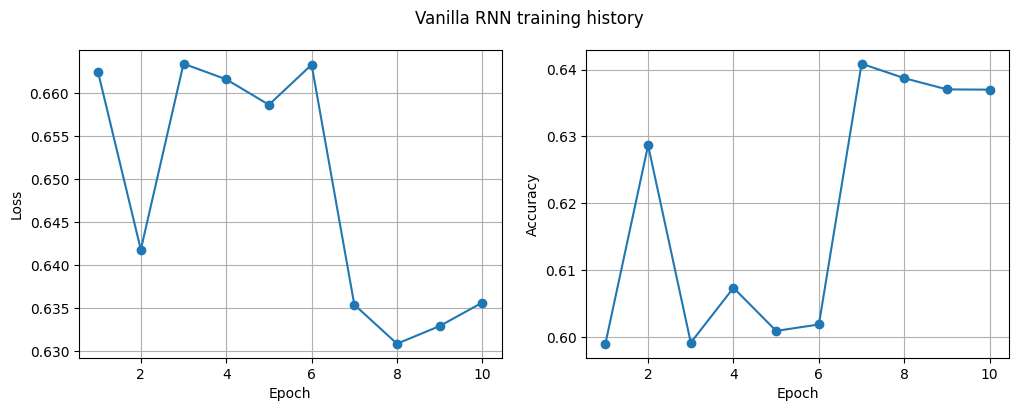

In [32]:
def plot_history(history, title="") -> None:
    """
    Takes in history dict returned by SentimentModel.train(), with one value per epoch for each metric
    Returns nothing, just plots every metric vs epoch side by side
    """
    epochs = range(1, len(history["loss"])+1) # 1-indexed, same as train()'s print!
    fig, axes = plt.subplots(1, len(history), figsize=(12, 4))
    for ax, (metric, values) in zip(axes, history.items()): # One subplot per metric
        ax.plot(epochs, values, marker="o")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.capitalize())
        ax.grid(True)
    fig.suptitle(f"{title} training history")
    plt.show()

plot_history(rnn_history, title="Vanilla RNN")

In [22]:
# One-shot example: predicting the sentiment of the first review in the test set
print("Test review:", " ".join(inv.get(t, "<unk>") for t in X_test[0] if t != PAD))

y_prob = rnn_model(X_test[:1]).item() # X_test[:1] keeps the batch dim, so it's a batch of one review -> one probability
print("Predicted:", "positive" if y_prob > 0.5 else "negative", f"(probability of positive = {y_prob:.4f})")
print("Actual:", "positive" if y_test[0] == 1 else "negative")

Test review: <start> this movie was so stupid i could not bare to watch the rest of this movie to think that the spoiled bitch suggested to see other people then walks right into another relationship 5 minutes after the <unk> was made i really felt sorry for the guy but then again for a guy like that to even consider letting his fiancé see other people to go along with her grand idea well i'm sorry but he deserved what he got and she was definitely not the best fish in the sea either he can do way way way better she had no tits to <unk> no nothing and you had to have known that she wanted this right from the start 5 years how on earth did they last that long
Predicted: negative (probability of positive = 0.4573)
Actual: negative


### Implementing LSTM from scratch

In [28]:
class LSTMCell(RecurrentCell):
    """
    Long Short-Term Memory Cell for recurrent layers.
    """

    def __init__(self, hidden_size, seed=None) -> None:
        super().__init__(hidden_size, seed=seed)
        self.gates = {"forget": "f", "input": "i", "candidate": "c", "output": "o"}

    def build(self, input_dim):
        self.xdim = input_dim

        # Initialising the three params for each of the four gates
        for gate in  self.gates.values():
            self.add_weight(f"W_{gate}x", (self.xdim, self.hdim))
            self.add_weight(f"W_{gate}h", (self.hdim, self.hdim))
            self.add_weight(f"b_{gate}", (1, self.hdim))

    def init_state(self):
        return (np.zeros((1, self.hdim)), np.zeros((1, self.hdim))) # (h_0, c_0)


    def forward(self, x_t, prev_state=None):
        x_t = np.atleast_2d(x_t)
        (h_t_minus_1, c_t_minus_1) = self.init_state() if prev_state is None else prev_state
        h_t_minus_1 = np.array(h_t_minus_1).reshape(-1, self.hdim)
        c_t_minus_1 = np.array(c_t_minus_1).reshape(-1, self.hdim)

        self.build(x_t.shape[-1])

        f_t = 1 / (1 + np.exp(-(x_t @ self.params["W_fx"] + h_t_minus_1 @ self.params["W_fh"] + self.params["b_f"])))
        i_t = 1 / (1 + np.exp(-(x_t @ self.params["W_ix"] + h_t_minus_1 @ self.params["W_ih"] + self.params["b_i"])))
        candidate_t = np.tanh(x_t @ self.params["W_cx"] + h_t_minus_1 @ self.params["W_ch"] + self.params["b_c"])
        o_t = 1 / (1 + np.exp(-(x_t @ self.params["W_ox"] + h_t_minus_1 @ self.params["W_oh"] + self.params["b_o"])))

        # Element-wise multiplication for new cell and hidden states
        c_t = f_t * c_t_minus_1 + i_t * candidate_t
        h_t = o_t * np.tanh(c_t)

        new_state = (h_t, c_t)
        cache = (x_t, h_t_minus_1, c_t_minus_1, f_t, i_t, candidate_t, o_t, c_t)
        return (new_state, cache)


    def backward(self, dstate, cache):
        """
        Takes in gradients of current hidden & cell states @ t and values used in current run
        Returns gradient of current input (= previous layer's output) and previous states @ t-1
        """
        (dh_t,dc_t) = dstate
        (x_t, h_t_minus_1, c_t_minus_1, f_t, i_t, candidate_t, o_t, c_t) = cache

        # h_t = o_t * tanh(c_t)
        tanh_c_t = np.tanh(c_t)
        do_t = tanh_c_t * dh_t
        dc_t += (dh_t * o_t) * (1 - tanh_c_t**2) # c_t gets grads from h_t and c_t+1 both!

        # c_t = f_t * c_t_minus_1 + i_t * candidate_t
        df_t = dc_t * c_t_minus_1
        di_t = dc_t * candidate_t
        dcandidate_t = dc_t * i_t
        dc_t_minus_1 = dc_t * f_t

        # Gradient through each activation using cached outputs
        da_f = df_t * f_t * (1 - f_t)
        da_i = di_t * i_t * (1 - i_t)
        da_c = dcandidate_t * (1 - candidate_t**2)
        da_o = do_t * o_t * (1 - o_t)

        dgates = {"f": da_f, "i": da_i, "c": da_c, "o": da_o}

        if self.grads is not None:
            for gate, da in dgates.items():
                self.grads[f"W_{gate}x"] += x_t.T @ da
                self.grads[f"W_{gate}h"] += h_t_minus_1.T @ da
                self.grads[f"b_{gate}"] += da.sum(axis=0, keepdims=True) # Sum over batch

        # As x_t and h_t_minus_1 feed all four gates, grads add up over the gates
        dx_t = sum(da @ self.params[f"W_{gate}x"].T for gate, da in dgates.items())
        dh_t_minus_1 = sum(da @ self.params[f"W_{gate}h"].T for gate, da in dgates.items())

        dprev_state = (dh_t_minus_1, dc_t_minus_1)
        return (dx_t, dprev_state)

### Applying custom LSTM for sentiment analysis

In [29]:
%%time
lstm_model = SentimentModel(embedding_matrix=E, layers=[
    RNNLayer(LSTMCell(hidden_size=64), return_sequences=False),
    Dense(n_neurons=1),
    Sigmoid()
])
lstm_history = lstm_model.train(X_train, y_train, BinaryCrossEntropy(), AdamOptimizer(lr=0.001), EPOCHS, batch_size=BATCH_SIZE, seed=SEED)

Epoch 1/10 - batch 20/391 - loss: 0.6933 - accuracy: 0.5305

KeyboardInterrupt: 

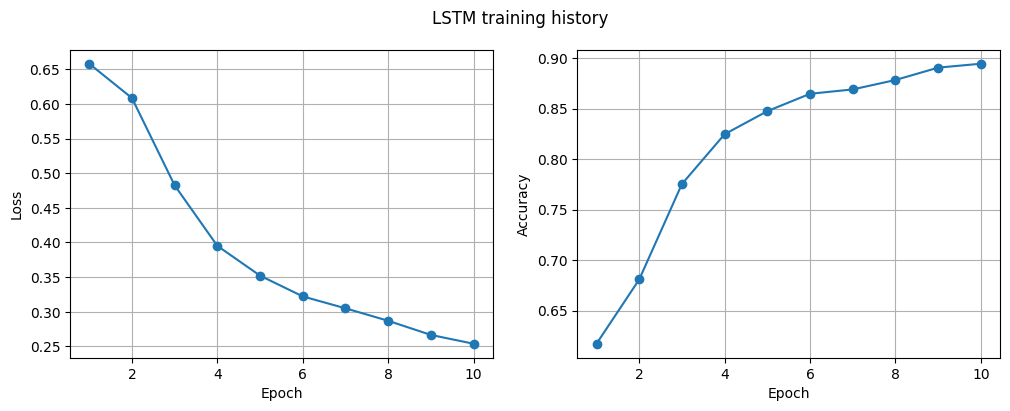

In [33]:
plot_history(lstm_history, title="LSTM")

In [25]:
# One-shot example: predicting the sentiment of the first review in the test set
print("Test review:", " ".join(inv.get(t, "<unk>") for t in X_test[0] if t != PAD))

y_prob = lstm_model(X_test[:1]).item() # X_test[:1] keeps the batch dim, so it's a batch of one review -> one probability
print("Predicted:", "positive" if y_prob > 0.5 else "negative", f"(probability of positive = {y_prob:.4f})")
print("Actual:", "positive" if y_test[0] == 1 else "negative")

Test review: <start> this movie was so stupid i could not bare to watch the rest of this movie to think that the spoiled bitch suggested to see other people then walks right into another relationship 5 minutes after the <unk> was made i really felt sorry for the guy but then again for a guy like that to even consider letting his fiancé see other people to go along with her grand idea well i'm sorry but he deserved what he got and she was definitely not the best fish in the sea either he can do way way way better she had no tits to <unk> no nothing and you had to have known that she wanted this right from the start 5 years how on earth did they last that long
Predicted: negative (probability of positive = 0.0105)
Actual: negative


## Q2: Comparing models
---

Compare both models based on various evaluation metrics using your results.

In [ ]:
# TODO: Helper function to evaluate model(s)

In [ ]:
# TODO: Evaluate + visualise rnn_model on test data

In [ ]:
# TODO: Evaluate lstm_model on test data

In [ ]:
# TODO: Evaluate & then compare rnn_model with lstm_model

In [ ]:
# TODO: Draw visualisations of comparision AND experimental results

## Review
---

Answer the following questions based on your experimental results:
<ol type="a">
    <li>Which model performed better and why?</li>
    <li>Draw suitable visualizations for the results using both models to make the experimental results more interpretable and write your observations.</li>
    <li>Compare based on trainable parameters.</li>
</ol>